# 🧠 Convolutional Neural Network 실습 (TensorFlow/Keras + MNIST)

이 노트북에서는 Convolution과 Pooling의 개념을 실습합니다.

## 주요 포인트
- Convolution: kernel size, padding, stride, dilation, filter 개수, bias
- Pooling: MaxPooling vs AveragePooling


In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


## [1] MNIST 데이터 로드 및 전처리

Train shape: (60000, 28, 28, 1)
Test shape: (10000, 28, 28, 1)


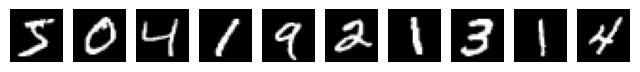

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

print('Train shape:', x_train.shape)
print('Test shape:', x_test.shape)

plt.figure(figsize=(8, 2))
for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.axis('off')
plt.show()

## [2] Convolution 실습
### 2.1 Kernel size & Padding

In [3]:
sample = x_train[0:1]

conv_valid = layers.Conv2D(filters=1, kernel_size=(3,3), padding='valid', use_bias=False)
conv_same = layers.Conv2D(filters=1, kernel_size=(3,3), padding='same', use_bias=False)

out_valid = conv_valid(sample)
out_same = conv_same(sample)

print('입력:', sample.shape)
print('valid 출력:', out_valid.shape)
print('same 출력:', out_same.shape)

입력: (1, 28, 28, 1)
valid 출력: (1, 26, 26, 1)
same 출력: (1, 28, 28, 1)


### 2.2 Stride와 Dilation

In [4]:
conv_stride = layers.Conv2D(1, (3,3), strides=(2,2), padding='same', use_bias=False)
conv_dilated = layers.Conv2D(1, (3,3), dilation_rate=(2,2), padding='same', use_bias=False)

out_stride = conv_stride(sample)
out_dilated = conv_dilated(sample)

print('stride=2 출력:', out_stride.shape)
print('dilation=2 출력:', out_dilated.shape)

stride=2 출력: (1, 14, 14, 1)
dilation=2 출력: (1, 28, 28, 1)


### 2.3 Filter 개수

출력 shape: (1, 28, 28, 8)


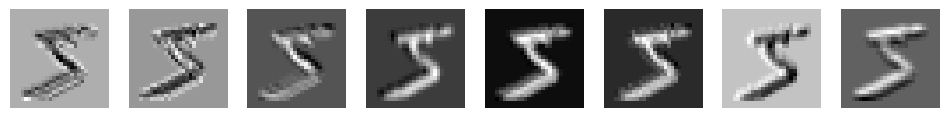

In [5]:
conv_multi = layers.Conv2D(8, (3,3), padding='same', use_bias=False)
out_multi = conv_multi(sample)
print('출력 shape:', out_multi.shape)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i in range(8):
    axes[i].imshow(out_multi[0, :, :, i], cmap='gray')
    axes[i].axis('off')
plt.show()

## [3] Pooling 실습

입력: (1, 28, 28, 1)
Max Pool 출력: (1, 14, 14, 1)
Avg Pool 출력: (1, 14, 14, 1)


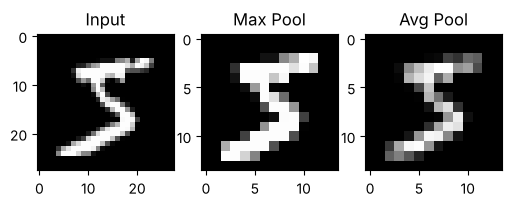

In [6]:
pool_max = layers.MaxPooling2D(pool_size=(2,2), strides=2)
pool_avg = layers.AveragePooling2D(pool_size=(2,2), strides=2)

out_max = pool_max(sample)
out_avg = pool_avg(sample)

print('입력:', sample.shape)
print('Max Pool 출력:', out_max.shape)
print('Avg Pool 출력:', out_avg.shape)

plt.figure(figsize=(6,2))
plt.subplot(1,3,1)
plt.title('Input')
plt.imshow(sample[0].squeeze(), cmap='gray')

plt.subplot(1,3,2)
plt.title('Max Pool')
plt.imshow(out_max[0], cmap='gray')

plt.subplot(1,3,3)
plt.title('Avg Pool')
plt.imshow(out_avg[0], cmap='gray')
plt.show()

## [4] CNN 간단 학습 실습

In [7]:
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.AveragePooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.1)
test_loss, test_acc = model.evaluate(x_test, y_test)
print('테스트 정확도:', test_acc)

Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.9141 - loss: 0.2921 - val_accuracy: 0.9787 - val_loss: 0.0783
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 29ms/step - accuracy: 0.9760 - loss: 0.0791 - val_accuracy: 0.9853 - val_loss: 0.0527
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 30ms/step - accuracy: 0.9824 - loss: 0.0572 - val_accuracy: 0.9853 - val_loss: 0.0534
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9853 - loss: 0.0463
테스트 정확도: 0.9853000044822693


---
## 📝 [실습 7-1 수행 결과 정리]

> 실행 환경: TensorFlow 2.21.0 / Keras 3.15.1 (CPU 2코어). 코드는 원본 그대로 실행했습니다. 노트북 출력에 없는 값(수용영역, 파라미터 분포, 학습된 필터, 이동 강건성)은 학습이 끝난 모델로 따로 측정했습니다.

### 1) Convolution 하이퍼파라미터 — 출력 크기 공식 검증

강의의 $O = \lfloor (I - F' + 2P)/S \rfloor + 1$ (dilation을 쓰면 유효 커널 $F' = F + (F-1)(d-1)$)로 노트북 출력이 모두 설명됩니다.

| 설정 (입력 28×28, 3×3 커널) | 노트북 출력 | 공식 계산 |
|:---|:---:|:---|
| `padding='valid'` | 26×26 | (28 − 3 + 0)/1 + 1 = 26 |
| `padding='same'` | 28×28 | P = 1 → (28 − 3 + 2)/1 + 1 = 28 |
| `strides=2` (same) | 14×14 | ⌊(28 − 3 + 2)/2⌋ + 1 = 14 |
| `dilation_rate=2` (same) | 28×28 | F' = 5, P = 2 → (28 − 5 + 4)/1 + 1 = 28 |
| (참고) dilation 2, valid | 24×24 | (28 − 5 + 0)/1 + 1 = 24 |

- dilation=2는 가중치 9개 그대로 5×5 영역을 봅니다. 파라미터를 늘리지 않고 수용영역을 키우는 방법입니다(강의 17~18쪽 WaveNet 예시).
- 2.3의 필터 8개 특징맵은 **학습 전 무작위 가중치**로 만든 것이라 엣지 방향이 임의로 나옵니다. 필터의 역할은 학습으로 정해집니다(아래 4번).

### 2) Pooling — Max vs Average (x_train[0], 숫자 5)

| 구분 | 크기 | 평균 밝기 | 획 픽셀 비율(>0.5) |
|:---|:---:|:---:|:---:|
| 입력 | 28×28 | 0.138 | 14.2% |
| Max Pooling | 14×14 | **0.212** | **21.9%** |
| Average Pooling | 14×14 | 0.138 | 14.3% |

- Max Pooling은 2×2 영역에서 가장 강한 반응만 남겨 **획이 두꺼워집니다**(평균 밝기 +54%). 작은 결함이나 강한 엣지를 놓치지 않아야 할 때 유리합니다.
- Average Pooling은 겹치지 않는 2×2 평균이라 **전체 밝기가 그대로 보존**되고 경계가 흐려집니다.

### 3) CNN 학습 결과 (3 Epoch, batch 128)

| Epoch | Train Acc | Val Acc | Val Loss |
|:---:|:---:|:---:|:---:|
| 1 | 0.9141 | 0.9787 | 0.0783 |
| 2 | 0.9760 | 0.9853 | 0.0527 |
| 3 | 0.9824 | 0.9853 | 0.0534 |

- **테스트 정확도 0.9853** (교수님 원본 출력 0.9882와 같은 수준이며, 차이는 가중치 초기값 차이). CPU 2코어에서 Epoch당 약 13~19초.
- Epoch 1에서 Val Acc가 Train Acc보다 높은 것은, Train 값이 Epoch 동안의 **평균**이라 학습 초반의 낮은 정확도가 섞여 있기 때문입니다(과소적합 아님).

**파라미터 분포 (총 121,930개)**

| 층 | 파라미터 | 비중 |
|:---|:---:|:---:|
| Conv2D(32, 3×3) | 320 | 0.3% |
| Conv2D(64, 3×3) | 18,496 | 15.2% |
| Dense(1600 → 64) | 102,464 | **84.0%** |
| Dense(64 → 10) | 650 | 0.5% |

- 특징을 뽑는 Conv 두 층은 합쳐서 15.5%뿐이고, Flatten 뒤 Dense 한 층이 84%를 차지합니다. 최근 CNN이 FC 대신 **Global Average Pooling**을 쓰는 이유가 이 숫자에 드러납니다(강의 11·33쪽).

**층별 수용영역** — $R_l = R_{l-1} + (K_l - 1) \times J_{l-1}$ ($J$ = 앞 층까지의 누적 stride)

| 층 | 출력 | 수용영역 | 누적 stride |
|:---|:---:|:---:|:---:|
| Conv 3×3 | 26×26×32 | 3×3 | 1 |
| MaxPool 2×2 | 13×13×32 | 4×4 | 2 |
| Conv 3×3 | 11×11×64 | 8×8 | 2 |
| AvgPool 2×2 | 5×5×64 | **10×10** | 4 |

- 마지막 특징맵의 한 칸은 입력 28×28 중 **10×10 영역**만 봅니다. 숫자 전체 모양은 그 뒤 Dense 층이 25개 위치의 특징을 조합해서 판단합니다.

### 4) 학습된 첫 번째 Conv 필터 (32개, 3×3)
- 가중치 합이 0에 가까운(밝기 **변화**에만 반응하는) 엣지형 필터 10개, 주변을 평균 내는 평활형 필터 14개가 생겼습니다.
- Sobel 수직 엣지 필터, 수평 엣지 필터와 코사인 유사도 0.7 이상인 필터가 **각각 6개**입니다(최고 0.95). 사람이 엣지 필터를 직접 설계하던 것을 CNN은 데이터에서 스스로 학습한다는 강의 7쪽 내용이 3 Epoch 학습만으로 확인됩니다.

### 5) 이동(Translation) 강건성 — CNN vs MLP
테스트 이미지를 오른쪽으로 k픽셀 옮겨 정확도를 다시 쟀습니다. 비교용 MLP(784-100-10, 79,510개)는 같은 조건(3 Epoch, batch 128)으로 따로 학습했습니다.

| 이동량 | 0px | 1px | 2px | 3px | 4px |
|:---|:---:|:---:|:---:|:---:|:---:|
| CNN (노트북 모델) | 0.985 | 0.980 | **0.958** | 0.876 | 0.685 |
| MLP | 0.963 | 0.918 | **0.724** | 0.493 | 0.304 |

- 2픽셀만 어긋나도 MLP는 24%p 떨어지지만 CNN은 2.7%p만 떨어집니다. 가중치 공유와 Pooling 덕분에 **위치가 조금 바뀌어도 같은 특징을 찾기** 때문입니다.
- 다만 CNN도 4픽셀(이미지 폭의 14%)에서는 68.5%까지 떨어집니다. Flatten + Dense가 위치마다 다른 가중치를 쓰므로 **완전한 이동 불변은 아닙니다**. 제조 비전 검사라면 제품 위치 정렬(지그, ROI 보정)이나 이동 Augmentation이 여전히 필요합니다.

### 6) 핵심 정리
1. 출력 크기는 kernel·padding·stride·dilation 공식으로 정확히 예측됩니다. `same`은 크기 유지, stride는 축소, dilation은 같은 파라미터로 수용영역 확대입니다.
2. Max Pooling은 강한 반응을 강조하고, Average Pooling은 평균을 보존합니다.
3. 파라미터의 84%가 FC 한 층에 몰려 있습니다. CNN의 효율은 Conv 층에서 나오며, FC는 GAP로 대체하는 추세입니다.
4. CNN은 MLP보다 위치 변화에 훨씬 강하지만 완전한 불변은 아니므로, 실제 검사 환경에서는 정렬·증강을 함께 써야 합니다.